# **Penting**
- Pastikan Anda melakukan Run All sebelum mengirimkan submission untuk memastikan seluruh cell berjalan dengan baik.
- Hapus simbol pagar (#) jika Anda menerapkan kriteria tambahan
- Biarkan simbol pagar (#) jika Anda tidak menerapkan kriteria tambahan

# **1. Import Library**
Pada tahap ini, Anda perlu mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning.

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import joblib # Untuk menyimpan model
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
PATH_TO_DATASET = '/content/drive/MyDrive/data_clustering_inverse.csv'
TARGET_COLUMN = 'Target'

# **2. Memuat Dataset dari Hasil Clustering**
Memuat dataset hasil clustering dari file CSV ke dalam variabel DataFrame.

In [7]:
try:
    df_classification = pd.read_csv(PATH_TO_DATASET)
    print(f"Loaded {os.path.basename(PATH_TO_DATASET)} for classification. Shape: {df_classification.shape}")
except FileNotFoundError:
    print(f"Error: {os.path.basename(PATH_TO_DATASET)} not found. Cannot proceed with classification.")
    print("Pastikan file berada di path yang benar atau sudah di-mount jika di Google Colab.")
    exit()
except Exception as e:
    print(f"An error occurred while loading the dataset: {e}")
    exit()
# Tampilkan 5 baris pertama dengan function head.
print("\nDataFrame Head:")
print(df_classification.head())
print("\nDataFrame Info:")
df_classification.info()

Loaded data_clustering_inverse.csv for classification. Shape: (2537, 17)

DataFrame Head:
   AccountBalance  CustomerAge  LoginAttempts  TransactionAmount  \
0         5112.21         70.0            1.0              14.09   
1        13758.91         68.0            1.0             376.24   
2         1122.35         19.0            1.0             126.29   
3         8569.06         26.0            1.0             184.50   
4         7429.40         45.0            1.0              13.45   

   TransactionDuration TransactionID AccountID      TransactionDate  \
0                 81.0      TX000001   AC00128  2023-04-11 16:29:14   
1                141.0      TX000002   AC00455  2023-06-27 16:44:19   
2                 56.0      TX000003   AC00019  2023-07-10 18:16:08   
3                 25.0      TX000004   AC00070  2023-05-05 16:32:11   
4                198.0      TX000005   AC00411  2023-10-16 17:51:24   

  TransactionType   Location DeviceID      IP Address MerchantID Channel  

In [17]:
# Identifikasi kolom non-numerik (object/string) yang bukan target
non_numeric_cols = df_classification.select_dtypes(include=['object', 'string']).columns.tolist()
# Pastikan kolom TARGET_COLUMN tidak ikut diproses sebagai fitur
if TARGET_COLUMN in non_numeric_cols:
    non_numeric_cols.remove(TARGET_COLUMN)
print(f"\nKolom non-numerik yang terdeteksi (akan diproses): {non_numeric_cols}")
if 'TX001653' in str(df_classification.values): # Ini hanya cek cepat jika nilai spesifik ada
    print("WARNING: Nilai 'TX001653' terdeteksi, kemungkinan ada kolom ID atau kode unik yang tidak numerik.")
# Untuk setiap kolom di non_numeric_cols yang BUKAN ID atau unik dan memiliki makna kategorikal
if len(non_numeric_cols) > 0:
    print(f"\nMelakukan One-Hot Encoding pada kolom: {non_numeric_cols}")
    df_classification = pd.get_dummies(df_classification, columns=non_numeric_cols, drop_first=True) # drop_first=True untuk menghindari dummy variable trap
    print("One-Hot Encoding selesai.")
else:
    print("\nTidak ada kolom 'object' atau 'string' yang perlu di-encode (selain target).")

print("\nDataFrame Head (Setelah Preprocessing):")
print(df_classification.head())
print("\nDataFrame Info (Setelah Preprocessing):")
df_classification.info()


Kolom non-numerik yang terdeteksi (akan diproses): []

Tidak ada kolom 'object' atau 'string' yang perlu di-encode (selain target).

DataFrame Head (Setelah Preprocessing):
   AccountBalance  CustomerAge  LoginAttempts  TransactionAmount  \
0         5112.21         70.0            1.0              14.09   
1        13758.91         68.0            1.0             376.24   
2         1122.35         19.0            1.0             126.29   
3         8569.06         26.0            1.0             184.50   
4         7429.40         45.0            1.0              13.45   

   TransactionDuration  Target  TransactionID_TX000002  \
0                 81.0       0                   False   
1                141.0       0                    True   
2                 56.0       3                   False   
3                 25.0       3                   False   
4                198.0       3                   False   

   TransactionID_TX000003  TransactionID_TX000004  TransactionID_TX0

In [18]:
# Gunakan dataset hasil clustering yang memiliki fitur Target
# Silakan gunakan dataset data_clustering jika tidak menerapkan Interpretasi Hasil Clustering [Advanced]
# Silakan gunakan dataset data_clustering_inverse jika menerapkan Interpretasi Hasil Clustering [Advanced]
binned_label_cols = [col for col in df_classification.columns if col.endswith('_Bin_Label')]
X = df_classification.drop([TARGET_COLUMN] + binned_label_cols, axis=1, errors='ignore') # Drop Target dan binned labels
y = df_classification[TARGET_COLUMN]

print(f"\nFeatures (X) shape: {X.shape}")
print(f"Target (y) shape: {y.shape}")
print(f"Target unique values: {y.unique()}")
print(f"Target value counts:\n{y.value_counts()}")


Features (X) shape: (2537, 7242)
Target (y) shape: (2537,)
Target unique values: [0 3 2 1]
Target value counts:
Target
0    1193
2     664
3     449
1     231
Name: count, dtype: int64


# **3. Data Splitting**
Tahap Data Splitting bertujuan untuk memisahkan dataset menjadi dua bagian: data latih (training set) dan data uji (test set).

In [19]:
# Menggunakan train_test_split() untuk melakukan pembagian dataset.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
print(f"\nTraining data shape (X_train, y_train): {X_train.shape}, {y_train.shape}")
print(f"Testing data shape (X_test, y_test): {X_test.shape}, {y_test.shape}")


Training data shape (X_train, y_train): (1775, 7242), (1775,)
Testing data shape (X_test, y_test): (762, 7242), (762,)


# **4. Membangun Model Klasifikasi**
Setelah memilih algoritma klasifikasi yang sesuai, langkah selanjutnya adalah melatih model menggunakan data latih.

Berikut adalah rekomendasi tahapannya.
1. Menggunakan algoritma klasifikasi yaitu Decision Tree.
2. Latih model menggunakan data yang sudah dipisah.

In [20]:
# Buatlah model klasifikasi menggunakan Decision Tree
# Model Decision Tree
dt_model = DecisionTreeClassifier(random_state=42)
print(f"  - Decision Tree Model initialized: {dt_model}")

# Model Random Forest (untuk kriteria Skilled)
rf_model = RandomForestClassifier(random_state=42)
print(f"  - Random Forest Model initialized: {rf_model}")

# Model Logistic Regression (untuk kriteria Skilled)
lr_model = LogisticRegression(random_state=42, solver='liblinear', max_iter=1000)
print(f"  - Logistic Regression Model initialized: {lr_model}")

  - Decision Tree Model initialized: DecisionTreeClassifier(random_state=42)
  - Random Forest Model initialized: RandomForestClassifier(random_state=42)
  - Logistic Regression Model initialized: LogisticRegression(max_iter=1000, random_state=42, solver='liblinear')


In [21]:
# Menyimpan Model
models_to_train = {
    'Decision Tree': dt_model,
    'Random Forest': rf_model,
    'Logistic Regression': lr_model
}
# Melatih setiap model yang telah didefinisikan
trained_models = {}
for name, model in models_to_train.items():
    print(f"\n  -- Training {name} Model --")
    model.fit(X_train, y_train)
    trained_models[name] = model
    print(f"  {name} Model training complete.")
# import joblib
joblib.dump(trained_models['Decision Tree'], 'decision_tree_model.h5')


  -- Training Decision Tree Model --
  Decision Tree Model training complete.

  -- Training Random Forest Model --
  Random Forest Model training complete.

  -- Training Logistic Regression Model --
  Logistic Regression Model training complete.


['decision_tree_model.h5']

# **5. Memenuhi Kriteria Skilled dan Advanced dalam Membangun Model Klasifikasi**



**Biarkan kosong jika tidak menerapkan kriteria skilled atau advanced**

In [22]:
# Melatih model menggunakan algoritma klasifikasi selain Decision Tree.
# Menyimpan Model
models_to_train = {
    'Decision Tree': dt_model,
    'Random Forest': rf_model,
    'Logistic Regression': lr_model
}
# Melatih setiap model yang telah didefinisikan
trained_models = {}
for name, model in models_to_train.items():
    print(f"\n  -- Training {name} Model --")
    model.fit(X_train, y_train)
    trained_models[name] = model
    print(f"  {name} Model training complete.")
# import joblib
joblib.dump(trained_models['Decision Tree'], 'decision_tree_model.h5')


  -- Training Decision Tree Model --
  Decision Tree Model training complete.

  -- Training Random Forest Model --
  Random Forest Model training complete.

  -- Training Logistic Regression Model --
  Logistic Regression Model training complete.


['decision_tree_model.h5']


--- 5. Evaluasi Model ---

--- Hasil Evaluasi Seluruh Algoritma ---

Model: Decision Tree
  Accuracy: 1.0000

  Classification Metrics (Per Class & Averages):
    Class 0:
      Precision: 1.0000
      Recall: 1.0000
      F1-Score: 1.0000
      Support: 358
    Class 1:
      Precision: 1.0000
      Recall: 1.0000
      F1-Score: 1.0000
      Support: 69
    Class 2:
      Precision: 1.0000
      Recall: 1.0000
      F1-Score: 1.0000
      Support: 200
    Class 3:
      Precision: 1.0000
      Recall: 1.0000
      F1-Score: 1.0000
      Support: 135
    Macro Avg:
      Precision: 1.0000
      Recall: 1.0000
      F1-Score: 1.0000
      Support: 762
    Weighted Avg:
      Precision: 1.0000
      Recall: 1.0000
      F1-Score: 1.0000
      Support: 762

  Confusion Matrix:
[[358   0   0   0]
 [  0  69   0   0]
 [  0   0 200   0]
 [  0   0   0 135]]

Model: Random Forest
  Accuracy: 0.9974

  Classification Metrics (Per Class & Averages):
    Class 0:
      Precision: 1.0000
      Re

<ipython-input-24-3ad29fa2ea74>:103: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='Accuracy', data=df_results_sorted, palette='viridis')


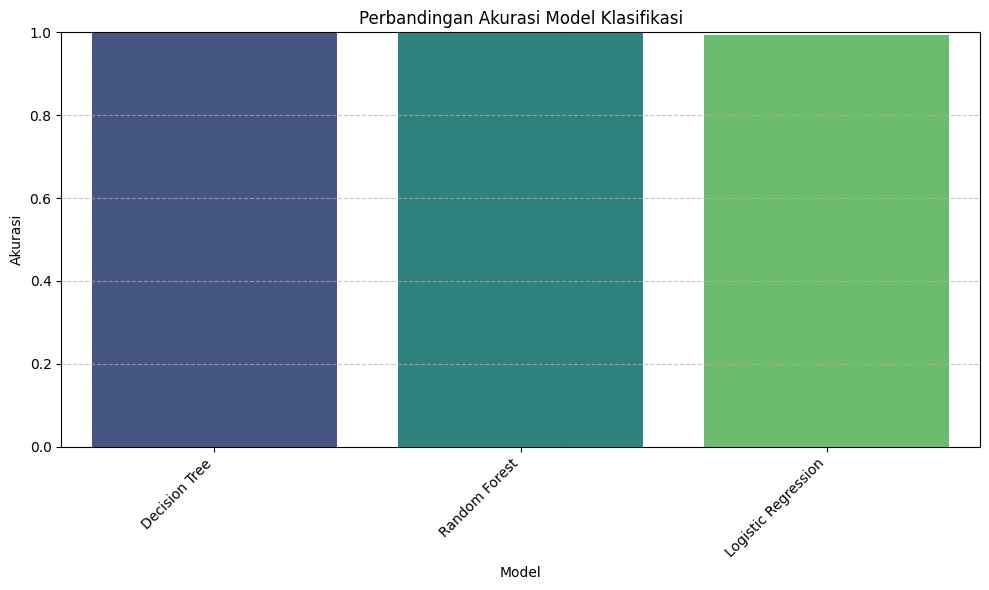

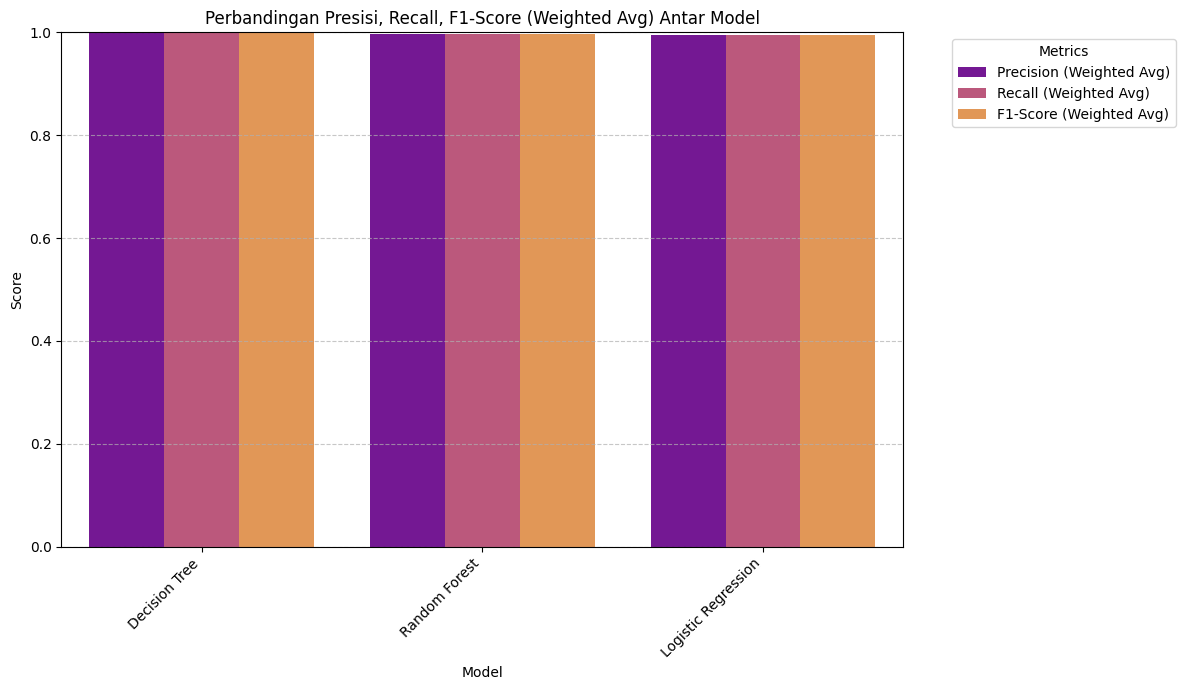

In [24]:
# Menampilkan hasil evaluasi akurasi, presisi, recall, dan F1-Score pada seluruh algoritma yang sudah dibuat.
print("\n--- 5. Evaluasi Model ---")

evaluations = {}
best_model_name = None
best_accuracy = -1.0 # Inisialisasi dengan nilai sangat rendah

print("\n--- Hasil Evaluasi Seluruh Algoritma ---")

# List untuk menyimpan ringkasan hasil agar mudah dibuat DataFrame
results_summary = []

for name, model in trained_models.items():
    print(f"\n=============================================")
    print(f"Model: {name}")
    print(f"=============================================")

    # Lakukan prediksi pada data testing
    y_pred = model.predict(X_test)

    # Hitung metrik evaluasi
    accuracy = accuracy_score(y_test, y_pred)
    # classification_report bisa langsung menghasilkan dictionary dengan output_dict=True
    report_dict = classification_report(y_test, y_pred, output_dict=True, zero_division=0) # zero_division=0 agar tidak error jika ada kelas tanpa sampel prediksi/asli
    conf_matrix = confusion_matrix(y_test, y_pred)

    # Simpan hasil evaluasi ke dictionary
    evaluations[name] = {
        'model': model, # Simpan juga objek modelnya
        'accuracy': accuracy,
        'report': report_dict,
        'confusion_matrix': conf_matrix
    }

    # Menampilkan Accuracy
    print(f"  Accuracy: {accuracy:.4f}")

    # Menampilkan Presisi, Recall, F1-Score (per kelas dan rata-rata)
    print("\n  Classification Metrics (Per Class & Averages):")
    for class_label, metrics in report_dict.items():
        if isinstance(metrics, dict): # Pastikan ini adalah metrik per kelas atau rata-rata
            # Tampilan lebih rapi untuk kelas atau rata-rata
            if class_label.replace('.', '').isdigit(): # Cek jika label adalah digit (kelas)
                 print(f"    Class {class_label}:")
            elif class_label in ['macro avg', 'weighted avg', 'accuracy']: # Cek untuk metrik rata-rata
                print(f"    {class_label.replace('_', ' ').title()}:")
            else: # Untuk metrik lain seperti 'support' atau jika ada label string
                continue # Lewati jika bukan metrik yang ingin ditampilkan di sini

            if 'precision' in metrics:
                print(f"      Precision: {metrics['precision']:.4f}")
            if 'recall' in metrics:
                print(f"      Recall: {metrics['recall']:.4f}")
            if 'f1-score' in metrics:
                print(f"      F1-Score: {metrics['f1-score']:.4f}")
            if 'support' in metrics and class_label not in ['accuracy']: # Support untuk kelas, bukan untuk 'accuracy'
                print(f"      Support: {int(metrics['support'])}")

    # Menampilkan Confusion Matrix
    print("\n  Confusion Matrix:")
    print(conf_matrix)

    # Perbarui model terbaik (untuk Kriteria Skilled)
    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_model_name = name

    # Simpan hasil untuk ringkasan tabel
    # Menggunakan .get() untuk menghindari KeyError jika suatu metrik tidak ada
    results_summary.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision (Macro Avg)': report_dict.get('macro avg', {}).get('precision', np.nan),
        'Recall (Macro Avg)': report_dict.get('macro avg', {}).get('recall', np.nan),
        'F1-Score (Macro Avg)': report_dict.get('macro avg', {}).get('f1-score', np.nan),
        'Precision (Weighted Avg)': report_dict.get('weighted avg', {}).get('precision', np.nan),
        'Recall (Weighted Avg)': report_dict.get('weighted avg', {}).get('recall', np.nan),
        'F1-Score (Weighted Avg)': report_dict.get('weighted avg', {}).get('f1-score', np.nan),
    })

# Membuat DataFrame dari ringkasan hasil
df_results = pd.DataFrame(results_summary)

print("\n\n--- Ringkasan Performa Model (DataFrame) ---")
# Sort by Accuracy untuk perbandingan yang lebih baik
df_results_sorted = df_results.sort_values(by='Accuracy', ascending=False)
# to_string() untuk menampilkan semua baris dan kolom tanpa truncating
print(df_results_sorted.to_string(index=False))

# Menyimpan model terbaik dari eksplorasi (Kriteria Skilled)
if best_model_name and best_model_name in trained_models:
    explore_best_model_filename = f'explore_{best_model_name.lower().replace(" ", "_")}_classification.h5'
    joblib.dump(trained_models[best_model_name], explore_best_model_filename)
    print(f"\nModel terbaik dari eksplorasi ('{best_model_name}') berhasil disimpan sebagai '{explore_best_model_filename}'.")
else:
    print("\nTidak ada model terbaik yang teridentifikasi atau model terbaik tidak ditemukan dalam trained_models.")

# --- Visualisasi Performa Model ---
print("\n--- Visualisasi Performa Model ---")

# Bar plot untuk Akurasi
plt.figure(figsize=(10, 6))
sns.barplot(x='Model', y='Accuracy', data=df_results_sorted, palette='viridis')
plt.title('Perbandingan Akurasi Model Klasifikasi')
plt.ylabel('Akurasi')
plt.ylim(0, 1) # Akurasi berkisar antara 0 dan 1
plt.xticks(rotation=45, ha='right') # Memutar label x agar tidak tumpang tindih
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Bar plot untuk Presisi, Recall, F1-Score (Weighted Average)
# Melelehkan DataFrame untuk plot yang lebih mudah dengan Seaborn
df_results_sorted_melted = df_results_sorted.melt(id_vars=['Model'],
                                                  value_vars=['Precision (Weighted Avg)', 'Recall (Weighted Avg)', 'F1-Score (Weighted Avg)'],
                                                  var_name='Metric', value_name='Score')

plt.figure(figsize=(12, 7))
sns.barplot(x='Model', y='Score', hue='Metric', data=df_results_sorted_melted, palette='plasma')
plt.title('Perbandingan Presisi, Recall, F1-Score (Weighted Avg) Antar Model')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Metrics', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


In [ ]:
# Menyimpan Model Selain Decision Tree
# Model ini bisa lebih dari satu
# import joblib
# joblib.dump(___, 'explore_<Nama Algoritma>_classification.h5')

Hyperparameter Tuning Model

Pilih salah satu algoritma yang ingin Anda tuning

In [25]:
# Lakukan Hyperparameter Tuning dan Latih ulang.
print("\n--- 5.a. Hyperparameter Tuning (Kriteria Advanced) ---")
worst_model_name = None
worst_accuracy = float('inf')
for model_name, eval_data in evaluations.items():
    if eval_data['accuracy'] < worst_accuracy:
        worst_accuracy = eval_data['accuracy']
        worst_model_name = model_name

print(f"\n  Model dengan akurasi terendah untuk tuning: {worst_model_name} (Accuracy: {worst_accuracy:.4f})")
tuned_model = None
tuned_model_name = None

if worst_model_name == 'Decision Tree':
    print("\n  Melakukan tuning untuk Decision Tree...")
    param_grid_dt = {
        'max_depth': [3, 5, 7, 9, 11, None],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4]
    }
    grid_search_dt = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid_dt, cv=5, scoring='accuracy', n_jobs=-1, verbose=1)
    grid_search_dt.fit(X_train, y_train)
    tuned_model = grid_search_dt.best_estimator_
    tuned_model_name = "Tuned Decision Tree"
    print(f"  Best parameters for Decision Tree: {grid_search_dt.best_params_}")

elif worst_model_name == 'Random Forest':
    print("\n  Melakukan tuning untuk Random Forest...")
    param_grid_rf = {
        'n_estimators': [50, 100, 150],
        'max_depth': [5, 10, None],
        'min_samples_split': [2, 5]
    }
    grid_search_rf = GridSearchCV(RandomForestClassifier(random_state=42), param_grid_rf, cv=5, scoring='accuracy', n_jobs=-1, verbose=1)
    grid_search_rf.fit(X_train, y_train)
    tuned_model = grid_search_rf.best_estimator_
    tuned_model_name = "Tuned Random Forest"
    print(f"  Best parameters for Random Forest: {grid_search_rf.best_params_}")

elif worst_model_name == 'Logistic Regression':
    print("\n  Melakukan tuning untuk Logistic Regression...")
    param_grid_lr = {
        'C': [0.01, 0.1, 1, 10, 100],
        'solver': ['liblinear', 'lbfgs']
    }
    grid_search_lr = GridSearchCV(LogisticRegression(random_state=42, max_iter=1000), param_grid_lr, cv=5, scoring='accuracy', n_jobs=-1, verbose=1)
    grid_search_lr.fit(X_train, y_train)
    tuned_model = grid_search_lr.best_estimator_
    tuned_model_name = "Tuned Logistic Regression"
    print(f"  Best parameters for Logistic Regression: {grid_search_lr.best_params_}")

else:
    print("  Tidak ada model yang diidentifikasi untuk tuning atau model terendah tidak dikenali.")

if tuned_model is not None:
    y_pred_tuned = tuned_model.predict(X_test)
    tuned_accuracy = accuracy_score(y_test, y_pred_tuned)
    print(f"\n  {tuned_model_name} Accuracy (after tuning): {tuned_accuracy:.4f}")
    print(f"  Classification Report ({tuned_model_name}):\n", classification_report(y_test, y_pred_tuned))
    print(f"  Confusion Matrix ({tuned_model_name}):\n", confusion_matrix(y_test, y_pred_tuned))
    joblib.dump(tuned_model, 'tuning_classification.h5')
    print(f"  Model hasil tuning ('{tuned_model_name}') berhasil disimpan sebagai 'tuning_classification.h5'.")



--- 5.a. Hyperparameter Tuning (Kriteria Advanced) ---

  Model dengan akurasi terendah untuk tuning: Logistic Regression (Accuracy: 0.9948)

  Melakukan tuning untuk Logistic Regression...
Fitting 5 folds for each of 10 candidates, totalling 50 fits
  Best parameters for Logistic Regression: {'C': 10, 'solver': 'liblinear'}

  Tuned Logistic Regression Accuracy (after tuning): 0.9961
  Classification Report (Tuned Logistic Regression):
               precision    recall  f1-score   support

           0       1.00      1.00      1.00       358
           1       1.00      0.97      0.99        69
           2       0.99      1.00      1.00       200
           3       1.00      0.99      1.00       135

    accuracy                           1.00       762
   macro avg       1.00      0.99      0.99       762
weighted avg       1.00      1.00      1.00       762

  Confusion Matrix (Tuned Logistic Regression):
 [[358   0   0   0]
 [  0  67   2   0]
 [  0   0 200   0]
 [  1   0   0 13

In [26]:
# Menampilkan hasil evaluasi akurasi, presisi, recall, dan F1-Score pada algoritma yang sudah dituning.
if tuned_model is not None:
    y_pred_tuned = tuned_model.predict(X_test)
    tuned_accuracy = accuracy_score(y_test, y_pred_tuned)
    print(f"\n  {tuned_model_name} Accuracy (after tuning): {tuned_accuracy:.4f}")
    print(f"  Classification Report ({tuned_model_name}):\n", classification_report(y_test, y_pred_tuned))
    print(f"  Confusion Matrix ({tuned_model_name}):\n", confusion_matrix(y_test, y_pred_tuned))
    joblib.dump(tuned_model, 'tuning_classification.h5')
    print(f"  Model hasil tuning ('{tuned_model_name}') berhasil disimpan sebagai 'tuning_classification.h5'.")



  Tuned Logistic Regression Accuracy (after tuning): 0.9961
  Classification Report (Tuned Logistic Regression):
               precision    recall  f1-score   support

           0       1.00      1.00      1.00       358
           1       1.00      0.97      0.99        69
           2       0.99      1.00      1.00       200
           3       1.00      0.99      1.00       135

    accuracy                           1.00       762
   macro avg       1.00      0.99      0.99       762
weighted avg       1.00      1.00      1.00       762

  Confusion Matrix (Tuned Logistic Regression):
 [[358   0   0   0]
 [  0  67   2   0]
 [  0   0 200   0]
 [  1   0   0 134]]
  Model hasil tuning ('Tuned Logistic Regression') berhasil disimpan sebagai 'tuning_classification.h5'.


In [27]:
# Menyimpan Model hasil tuning
# import joblib
# joblib.dump(model_dt, 'tuning_classification.h5')
if tuned_model is not None:
    y_pred_tuned = tuned_model.predict(X_test)
    tuned_accuracy = accuracy_score(y_test, y_pred_tuned)
    print(f"\n  {tuned_model_name} Accuracy (after tuning): {tuned_accuracy:.4f}")
    print(f"  Classification Report ({tuned_model_name}):\n", classification_report(y_test, y_pred_tuned))
    print(f"  Confusion Matrix ({tuned_model_name}):\n", confusion_matrix(y_test, y_pred_tuned))
    joblib.dump(tuned_model, 'tuning_classification.h5')
    print(f"  Model hasil tuning ('{tuned_model_name}') berhasil disimpan sebagai 'tuning_classification.h5'.")



  Tuned Logistic Regression Accuracy (after tuning): 0.9961
  Classification Report (Tuned Logistic Regression):
               precision    recall  f1-score   support

           0       1.00      1.00      1.00       358
           1       1.00      0.97      0.99        69
           2       0.99      1.00      1.00       200
           3       1.00      0.99      1.00       135

    accuracy                           1.00       762
   macro avg       1.00      0.99      0.99       762
weighted avg       1.00      1.00      1.00       762

  Confusion Matrix (Tuned Logistic Regression):
 [[358   0   0   0]
 [  0  67   2   0]
 [  0   0 200   0]
 [  1   0   0 134]]
  Model hasil tuning ('Tuned Logistic Regression') berhasil disimpan sebagai 'tuning_classification.h5'.
